In [2]:
#pip install requests pandas pyarrow

# Import data

In [3]:
import json
from datetime import datetime, timezone
from pathlib import Path

import pandas as pd
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

BASE_URL = "https://www.datos.gov.co"
DATASET_ID = "jbjy-vk9h"
OUTPUT_DIR = Path("data/raw")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

columns = [
    "id_contrato",
    "nombre_entidad",
    "departamento",
    "ciudad",
    "tipo_de_contrato",
    "modalidad_de_contratacion",
    "codigo_de_categoria_principal",
    "estado_contrato",
    "valor_del_contrato",
    "fecha_de_firma",
    "fecha_de_inicio_del_contrato",
    "fecha_de_fin_del_contrato",
    "dias_adicionados",
    "ultima_actualizacion",
]

params = {
    #"$select": ",".join(columns),
    "$where": (
        "fecha_de_firma >= '2022-08-30T00:00:00' "
        "AND fecha_de_firma < '2026-08-07T00:00:00'"
    ),
    "$order": "fecha_de_firma ASC, id_contrato ASC",
    "$limit": 5000,
}

session = requests.Session()
retries = Retry(
    total=3,
    backoff_factor=1,
    status_forcelist=[429, 500, 502, 503, 504],
)
session.mount("https://", HTTPAdapter(max_retries=retries))

response = session.get(
    f"{BASE_URL}/resource/{DATASET_ID}.json",
    params=params,
    timeout=120,
)
response.raise_for_status()
records = response.json()

if not isinstance(records, list) or not records:
    raise RuntimeError("The API did not return a nonempty list of records.")

# Preserve the response before converting any values.
with (OUTPUT_DIR / "contracts_sample.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(records, file, ensure_ascii=False, indent=2)

#df = pd.DataFrame(records).reindex(columns=columns)
df = pd.DataFrame(records)

# Socrata JSON commonly returns numbers as strings.
for column in ["valor_del_contrato", "dias_adicionados"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

for column in [
    "fecha_de_firma",
    "fecha_de_inicio_del_contrato",
    "fecha_de_fin_del_contrato",
    "ultima_actualizacion",
]:
    df[column] = pd.to_datetime(df[column], errors="coerce")

df.to_parquet(OUTPUT_DIR / "contracts_sample.parquet", index=False)
df.to_csv(
    OUTPUT_DIR / "contracts_sample.csv",
    index=False,
    encoding="utf-8-sig",
)

metadata_response = session.get(
    f"{BASE_URL}/api/views/{DATASET_ID}.json",
    timeout=60,
)
metadata_response.raise_for_status()

with (OUTPUT_DIR / "source_metadata.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(
        metadata_response.json(),
        file,
        ensure_ascii=False,
        indent=2,
    )

manifest = {
    "dataset_id": DATASET_ID,
    "extracted_at_utc": datetime.now(timezone.utc).isoformat(),
    "query_parameters": params,
    "row_count": len(df),
    "sample_cap": 5000,
}

with (OUTPUT_DIR / "extraction_manifest.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(manifest, file, ensure_ascii=False, indent=2)

print(f"Downloaded {len(df):,} records.")
print(f"Duplicate contract IDs: {df['id_contrato'].duplicated().sum():,}")
print("\nMissing values (%):")
print((df.isna().mean() * 100).round(1).sort_values(ascending=False))

if len(df) == params["$limit"]:
    print(
        "\nThe sample cap was reached. This is not necessarily "
        "the complete dataset."
    )


Downloaded 5,000 records.
Duplicate contract IDs: 0

Missing values (%):
fecha_inicio_reversi_n                                     99.9
fecha_fin_obligaciones_posconsumo                          99.9
fecha_inicio_obligaciones_posconsumo                       99.9
fecha_fin_reversi_n                                        99.9
fecha_de_notificaci_n_de_prorrogaci_n                      92.5
                                                           ... 
requisitos_ambientales_en_las_especificaciones_t_cnicas     0.0
criterios_de_sostenibilidad_ambiental                       0.0
direcci_n_de_ejecuci_n_del_contrato                         0.0
descripcion_documentos_tipo                                 0.0
obligaciones_posconsumo                                     0.0
Length: 95, dtype: float64

The sample cap was reached. This is not necessarily the complete dataset.


# Prep of dataset

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 95 columns):
 #   Column                                                            Non-Null Count  Dtype         
---  ------                                                            --------------  -----         
 0   nombre_entidad                                                    5000 non-null   object        
 1   nit_entidad                                                       5000 non-null   object        
 2   departamento                                                      5000 non-null   object        
 3   ciudad                                                            5000 non-null   object        
 4   localizaci_n                                                      5000 non-null   object        
 5   orden                                                             5000 non-null   object        
 6   sector                                                            5000 n

### Turn values into numeric columns

In [5]:
keywords = ['valor', 'saldo', 'duraci']

filtered_df = df.filter(regex=f"(?i){'|'.join(keywords)}")

In [6]:
filtered_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   valor_del_contrato            5000 non-null   float64
 1   valor_de_pago_adelantado      5000 non-null   object 
 2   valor_facturado               5000 non-null   object 
 3   valor_pendiente_de_pago       5000 non-null   object 
 4   valor_pagado                  5000 non-null   object 
 5   valor_amortizado              5000 non-null   object 
 6   valor_pendiente_de            5000 non-null   object 
 7   valor_pendiente_de_ejecucion  5000 non-null   object 
 8   saldo_cdp                     5000 non-null   object 
 9   saldo_vigencia                5000 non-null   object 
 10  duraci_n_del_contrato         5000 non-null   object 
dtypes: float64(1), object(10)
memory usage: 429.8+ KB


In [7]:
filtered_df

,valor_del_contrato,valor_de_pago_adelantado,valor_facturado,valor_pendiente_de_pago,valor_pagado,valor_amortizado,valor_pendiente_de,valor_pendiente_de_ejecucion,saldo_cdp,saldo_vigencia,duraci_n_del_contrato
0,16050000.0,0,13500000,2550000,13500000,0,0,2550000,16800000,0,107 Dia(s)
1,42397320.0,0,0,42397320,0,0,0,42397320,48000000,0,12 Mes(es)
2,45839080.0,0,45839080,0,45839080,0,0,0,57034800,0,220 Dia(s)
3,26000000.0,0,26000000,0,26000000,0,0,0,37500000,0,213 Dia(s)
4,12400000.0,0,0,12400000,0,0,0,12400000,14000000,0,45 Dia(s)
...,...,...,...,...,...,...,...,...,...,...,...
4995,3800041.0,0,2703875,1096166,2703875,0,0,1096166,3800041,0,106 Dia(s)
4996,6000000.0,0,6000000,0,6000000,0,0,0,6000000,0,3 Mes(es)
4997,7117950.0,0,7117950,0,7117950,0,0,0,7117950,0,105 Dia(s)
4998,13936667.0,0,13936667,0,13936667,0,0,0,14000000,0,113 Dia(s)


#### Duration

In [8]:
# Get the unique types of durations
type_of_duration = filtered_df['duraci_n_del_contrato'].str.split().str[1].unique()

In [9]:
# Make dictionary to translate durations to days
in_days = [1,30.5,365,0.04167, 0.25]
dict_duration = dict(zip(type_of_duration, in_days))
dict_duration

{'Dia(s)': 1,
 'Mes(es)': 30.5,
 'Año(s)': 365,
 'Hora(s)': 0.04167,
 'Semana(s)': 0.25}

In [10]:
filtered_df['en_dias'] = filtered_df['duraci_n_del_contrato'].str.split().str[1].map(dict_duration)

C:\Users\DAvega01\AppData\Local\Temp\ipykernel_51148\3103509225.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df['en_dias'] = filtered_df['duraci_n_del_contrato'].str.split().str[1].map(dict_duration)


In [11]:
filtered_df[['en_dias','duraci_n_del_contrato']].head()

,en_dias,duraci_n_del_contrato
0,1.0,107 Dia(s)
1,30.5,12 Mes(es)
2,1.0,220 Dia(s)
3,1.0,213 Dia(s)
4,1.0,45 Dia(s)


In [12]:
df['duration_in_days'] = (
    pd.to_numeric(filtered_df['duraci_n_del_contrato'].str.split().str[0], errors='coerce') 
    * filtered_df['en_dias']
)

In [13]:
df[['duration_in_days','duraci_n_del_contrato']]

,duration_in_days,duraci_n_del_contrato
0,107.0,107 Dia(s)
1,366.0,12 Mes(es)
2,220.0,220 Dia(s)
3,213.0,213 Dia(s)
4,45.0,45 Dia(s)
...,...,...
4995,106.0,106 Dia(s)
4996,91.5,3 Mes(es)
4997,105.0,105 Dia(s)
4998,113.0,113 Dia(s)


#### Other

In [14]:
filtered_df.drop(columns=['duraci_n_del_contrato', 'en_dias'], inplace=True)

C:\Users\DAvega01\AppData\Local\Temp\ipykernel_51148\1317224291.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df.drop(columns=['duraci_n_del_contrato', 'en_dias'], inplace=True)


In [15]:
df[filtered_df.columns] = filtered_df.apply(pd.to_numeric, errors='coerce')

In [16]:
df.describe()

,fecha_de_firma,fecha_de_inicio_del_contrato,fecha_de_fin_del_contrato,valor_del_contrato,valor_de_pago_adelantado,valor_facturado,valor_pendiente_de_pago,valor_pagado,valor_amortizado,valor_pendiente_de,valor_pendiente_de_ejecucion,saldo_cdp,saldo_vigencia,dias_adicionados,ultima_actualizacion,duration_in_days
count,5000,4954,5000,5.000000e+03,5.000000e+03,5.000000e+03,5.000000e+03,5.000000e+03,5.000000e+03,5.000000e+03,5.000000e+03,5.000000e+03,5.000000e+03,5000.00000,3504,5000.000000
mean,2022-08-30 23:31:58.892204032,2022-09-03 02:28:19.155429888,2023-01-08 03:45:09.024000,7.961033e+07,2.142850e+05,3.617327e+07,5.271570e+07,2.689462e+07,1.400000e+03,2.128850e+05,5.271570e+07,3.312650e+08,2.209324e+07,2.48480,2023-09-25 15:28:19.573568768,127.913834
min,2022-08-30 00:21:53.882000,2022-08-30 06:00:00,2022-08-30 11:00:00,0.000000e+00,0.000000e+00,0.000000e+00,-3.433330e+05,0.000000e+00,0.000000e+00,0.000000e+00,-3.433330e+05,0.000000e+00,0.000000e+00,0.00000,2022-08-30 15:14:21.115000,0.166680
25%,2022-08-30 14:37:37.847000064,2022-08-31 08:00:00,2022-12-15 12:00:00,7.619322e+06,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,8.400000e+06,0.000000e+00,0.00000,2023-03-03 03:22:03.589500160,95.000000
50%,2022-08-30 18:47:33.992000,2022-09-01 08:00:00,2022-12-29 23:00:00,1.225000e+07,0.000000e+00,5.981229e+06,4.858448e+06,2.000000e+06,0.000000e+00,0.000000e+00,4.858448e+06,1.520000e+07,0.000000e+00,0.00000,2023-07-31 14:47:19.647499776,120.000000
75%,2022-08-31 11:29:39.833750016,2022-09-02 08:00:00,2022-12-31 12:00:00,1.945742e+07,0.000000e+00,1.274414e+07,1.286400e+07,1.115484e+07,0.000000e+00,0.000000e+00,1.286400e+07,5.124013e+07,0.000000e+00,0.00000,2023-12-06 10:37:33.912000,122.000000
max,2022-08-31 16:46:17.361000,2023-06-29 12:00:00,2032-08-09 12:00:00,1.644497e+10,7.574250e+08,1.644497e+10,1.644497e+10,8.268550e+09,7.000000e+06,7.574250e+08,1.644497e+10,2.224445e+11,2.187150e+10,1095.00000,2026-11-23 14:50:23.438000,3650.000000
std,NaN,NaN,NaN,5.966329e+08,1.152208e+07,3.644470e+08,5.462455e+08,2.345001e+08,9.899495e+04,1.152083e+07,5.462455e+08,3.403273e+09,4.834677e+08,23.97199,NaN,164.011987


Hay columnas cuyos valores de percentil siguen siendo 0. Esto sugiere que la mayoría de valores son 0. Voy a guardar en un dataFrame nuevo y las elimino del dataframe principal.

In [17]:
almost_empty=['valor_de_pago_adelantado','valor_amortizado', 'valor_pendiente_de', 'saldo_vigencia', 'dias_adicionados']
df[almost_empty].describe()

,valor_de_pago_adelantado,valor_amortizado,valor_pendiente_de,saldo_vigencia,dias_adicionados
count,5.000000e+03,5.000000e+03,5.000000e+03,5.000000e+03,5000.00000
mean,2.142850e+05,1.400000e+03,2.128850e+05,2.209324e+07,2.48480
std,1.152208e+07,9.899495e+04,1.152083e+07,4.834677e+08,23.97199
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.00000
25%,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.00000
50%,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.00000
75%,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.00000
max,7.574250e+08,7.000000e+06,7.574250e+08,2.187150e+10,1095.00000


In [18]:
for c in almost_empty:
    print(df[c].value_counts())

valor_de_pago_adelantado
0.000000e+00    4997
7.574250e+08       1
1.400000e+07       1
3.000000e+08       1
Name: count, dtype: int64
valor_amortizado
0.000000e+00    4999
7.000000e+06       1
Name: count, dtype: int64
valor_pendiente_de
0.000000e+00    4997
7.574250e+08       1
7.000000e+06       1
3.000000e+08       1
Name: count, dtype: int64
saldo_vigencia
0              4952
1724954890        5
2468218400        4
905545644         4
2690062136        2
829998028         2
12543300000       2
961457036         2
77561312          1
123537429         1
207684750         1
20000000          1
512684847         1
3888000000        1
195399990         1
10200000          1
16641900000       1
40000000          1
1800000000        1
1254000000        1
75000000          1
30000000          1
845007213         1
6789960           1
7400000           1
4319160037        1
1962587           1
224014370         1
60000000          1
500057475         1
126154050         1
465203568       

In [19]:
financial_cols = [
    "valor_de_pago_adelantado",
    "valor_amortizado",
    "valor_pendiente_de",
    "saldo_vigencia",
]

# Convert in the analytical copy; preserve your original raw data.
financial = df[financial_cols].apply(
    pd.to_numeric,
    errors="coerce",
)

# Missing values do not count as recorded nonzero amounts.
has_nonzero = (
    financial.notna() & financial.ne(0)
).any(axis=1)

review_cols = [
    "id_contrato",
    "nombre_entidad",
    "tipo_de_contrato",
    "estado_contrato",
    "valor_del_contrato",
    *financial_cols,
]

financial_review = df.loc[has_nonzero, review_cols]

In [20]:
financial_review.describe(include='object')

,id_contrato,nombre_entidad,tipo_de_contrato,estado_contrato
count,51,51,51,51
unique,51,22,8,4
top,CO1.PCCNTR.3968432,CORPORACION AUTONOMA REGIONAL DE CUNDINAMARCA ...,Prestación de servicios,terminado
freq,1,21,41,18


In [21]:
# Erase almost_empty from df. Holding it now, but good for analysis in almost_empty
#df.drop(columns=almost_empty, inplace=True)

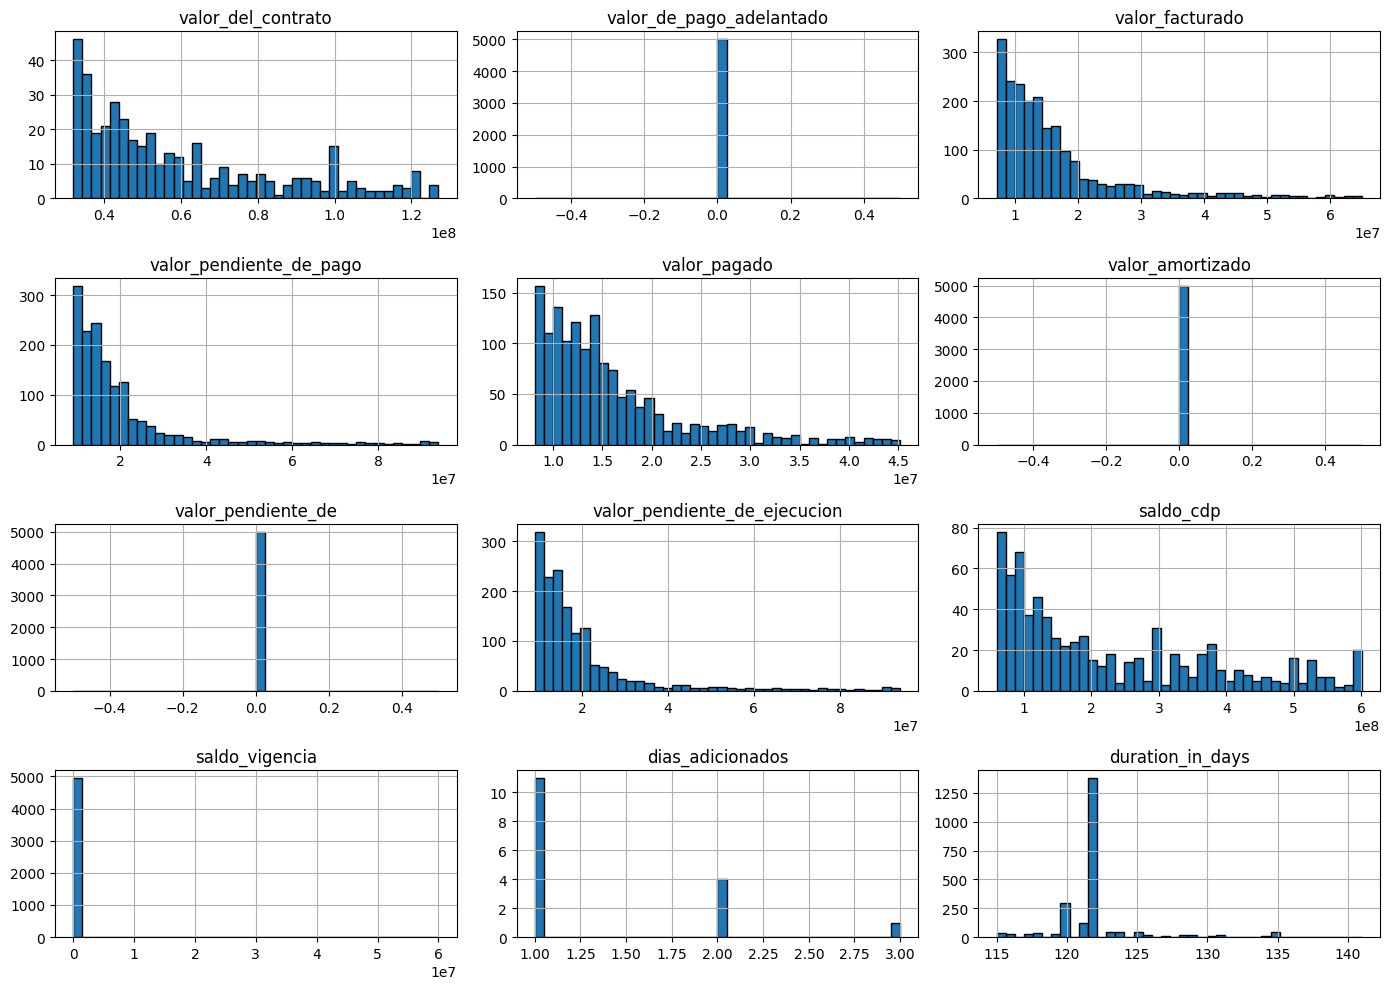

In [22]:
import matplotlib.pyplot as plt

num_df = df.select_dtypes(include='number')

# Calculate average (mean) and standard deviation (std)
mean = num_df.mean()
std = num_df.std()

# Keep only values within X standard deviations from the average (adjust X as needed)
x = 0.08
clean_df = num_df[(num_df - mean).abs() <= x * std]

# Plot clean histograms
clean_df.hist(bins=40, figsize=(14, 10), edgecolor='black')
plt.tight_layout()
plt.show()


Lo transformo todo a millones para entender mejor: 

In [23]:
df[[
    'valor_del_contrato', 
    'valor_facturado', 
    'valor_pendiente_de_pago', 
    'valor_pagado', 
    'valor_pendiente_de_ejecucion', 
    'saldo_cdp'
    ]] = df[[
        'valor_del_contrato', 
        'valor_facturado', 
        'valor_pendiente_de_pago', 
        'valor_pagado', 
        'valor_pendiente_de_ejecucion', 
        'saldo_cdp'
        ]] / 1e6

In [24]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import cbook

_VALID_SCALES = ('linear', 'log', 'symlog')

# matplotlib 3.10 replaced boxplot(vert=False) with orientation='horizontal'
_MPL_VERSION = tuple(int(p) for p in matplotlib.__version__.split('.')[:2])
_HBOX_KW = {'orientation': 'horizontal'} if _MPL_VERSION >= (3, 10) else {'vert': False}


def plot_histograms(
    data,
    columns=None,
    x_scale='log',
    y_scale='linear',
    bins=30,
    ncols=1,
    n_std=None,
    boxplot=True,
    box_ratio=0.25,
    title_size=20,
    tick_size=20,
    width=15,
    row_height=3.5,
    edgecolor='black',
    show=True,
):
    """Plot one histogram per numeric column, with a horizontal boxplot underneath
    that shares the histogram's x-axis (same scale and limits).

    Parameters
    ----------
    data : DataFrame or Series
    columns : list of column names to plot (default: every numeric column)
    x_scale, y_scale : 'linear', 'log' or 'symlog'
        Strict 'log' on x drops values <= 0 and uses log-spaced bins.
    bins : number of bins
    ncols : plots per row
    n_std : keep only values within mean +/- n_std standard deviations
        (per column; None = keep everything). With x_scale='log' the mean and
        std are computed on log10(values), so the cut is symmetric on the axis.
        The number of values kept is shown at the top right of each plot.
    boxplot : draw the boxplot under each histogram
    box_ratio : boxplot height as a fraction of the histogram height
    title_size, tick_size : font sizes
    width, row_height : figure width and height of each histogram row (inches)
    show : call plt.show() at the end

    Returns
    -------
    fig, axes
        axes has shape (n_columns, 2): axes[i, 0] is the histogram and
        axes[i, 1] the boxplot (None when boxplot=False).
    """
    if x_scale not in _VALID_SCALES or y_scale not in _VALID_SCALES:
        raise ValueError(f"x_scale and y_scale must be one of {_VALID_SCALES}")

    if isinstance(data, pd.Series):
        data = data.to_frame()
    if columns is None:
        columns = data.select_dtypes(include='number').columns
    columns = list(columns)
    if not columns:
        raise ValueError("No columns to plot.")

    nrows = math.ceil(len(columns) / ncols)
    panel_height = row_height * (1 + box_ratio) if boxplot else row_height
    fig = plt.figure(figsize=(width, panel_height * nrows), layout='constrained')
    # One subfigure per column keeps each histogram/boxplot pair tight together
    # while leaving room for titles between pairs.
    subfigs = np.atleast_1d(fig.subfigures(nrows, ncols, squeeze=False)).flatten()

    axes = np.empty((len(columns), 2), dtype=object)

    for i, (sf, col) in enumerate(zip(subfigs, columns)):
        if boxplot:
            ax_hist, ax_box = sf.subplots(
                2, 1, sharex=True, gridspec_kw={'height_ratios': [1, box_ratio]}
            )
        else:
            ax_hist, ax_box = sf.subplots(1, 1), None
        axes[i] = ax_hist, ax_box

        values = data[col].dropna()
        if x_scale == 'log':
            values = values[values > 0]  # log axis can't show zeros/negatives

        ax_hist.set_title(col, fontsize=title_size, fontweight='bold')

        if n_std is not None and len(values) > 1:
            n_before = len(values)
            scaled = np.log10(values) if x_scale == 'log' else values
            mean, std = scaled.mean(), scaled.std()
            if std > 0:
                values = values[(scaled - mean).abs() <= n_std * std]
            ax_hist.set_title(f'{len(values):,} of {n_before:,} within ±{n_std}σ',
                              loc='right', fontsize=tick_size * 0.8)
        for ax in (ax_hist, ax_box):
            if ax is not None:
                ax.tick_params(axis='both', which='both', labelsize=tick_size)

        if values.empty:
            ax_hist.text(0.5, 0.5, 'No data to plot', ha='center', va='center',
                         transform=ax_hist.transAxes, fontsize=tick_size)
            ax_hist.set_xticks([])
            ax_hist.set_yticks([])
            if ax_box is not None:
                ax_box.set_visible(False)
            continue

        has_range = values.min() < values.max()
        if x_scale == 'log' and has_range:
            col_bins = np.logspace(np.log10(values.min()), np.log10(values.max()), bins + 1)
        else:
            col_bins = bins

        ax_hist.hist(values, bins=col_bins, edgecolor=edgecolor, log=(y_scale == 'log'))

        if y_scale == 'symlog':
            ax_hist.set_yscale('symlog')

        if ax_box is not None:
            if x_scale == 'log':
                # Compute quartiles/whiskers in log space so the 1.5*IQR rule
                # matches what the log axis shows (otherwise almost every large
                # value gets flagged as an outlier).
                stats = cbook.boxplot_stats(np.log10(values.to_numpy()))
                for s in stats:
                    for k in ('med', 'q1', 'q3', 'whislo', 'whishi', 'mean', 'cilo', 'cihi'):
                        s[k] = 10 ** s[k]
                    s['fliers'] = 10 ** s['fliers']
                ax_box.bxp(stats, widths=0.6, **_HBOX_KW)
            else:
                ax_box.boxplot(values, widths=0.6, **_HBOX_KW)
            ax_box.set_yticks([])
            # Tick labels only on the bottom (boxplot) axis of each pair
            ax_hist.tick_params(axis='x', which='both', labelbottom=False)

        # Set after plotting: shared x-axes share scale and limits, so the
        # boxplot lines up exactly with the histogram bins.
        if x_scale != 'linear' and has_range:
            ax_hist.set_xscale(x_scale)

    # Hide unused subfigure slots
    for sf in subfigs[len(columns):]:
        sf.set_visible(False)

    if show:
        plt.show()
    return fig, axes


# Example usage
#fig, axes = plot_histograms(clean_df, x_scale='log', y_scale='linear', n_std=2)


In [26]:
import math

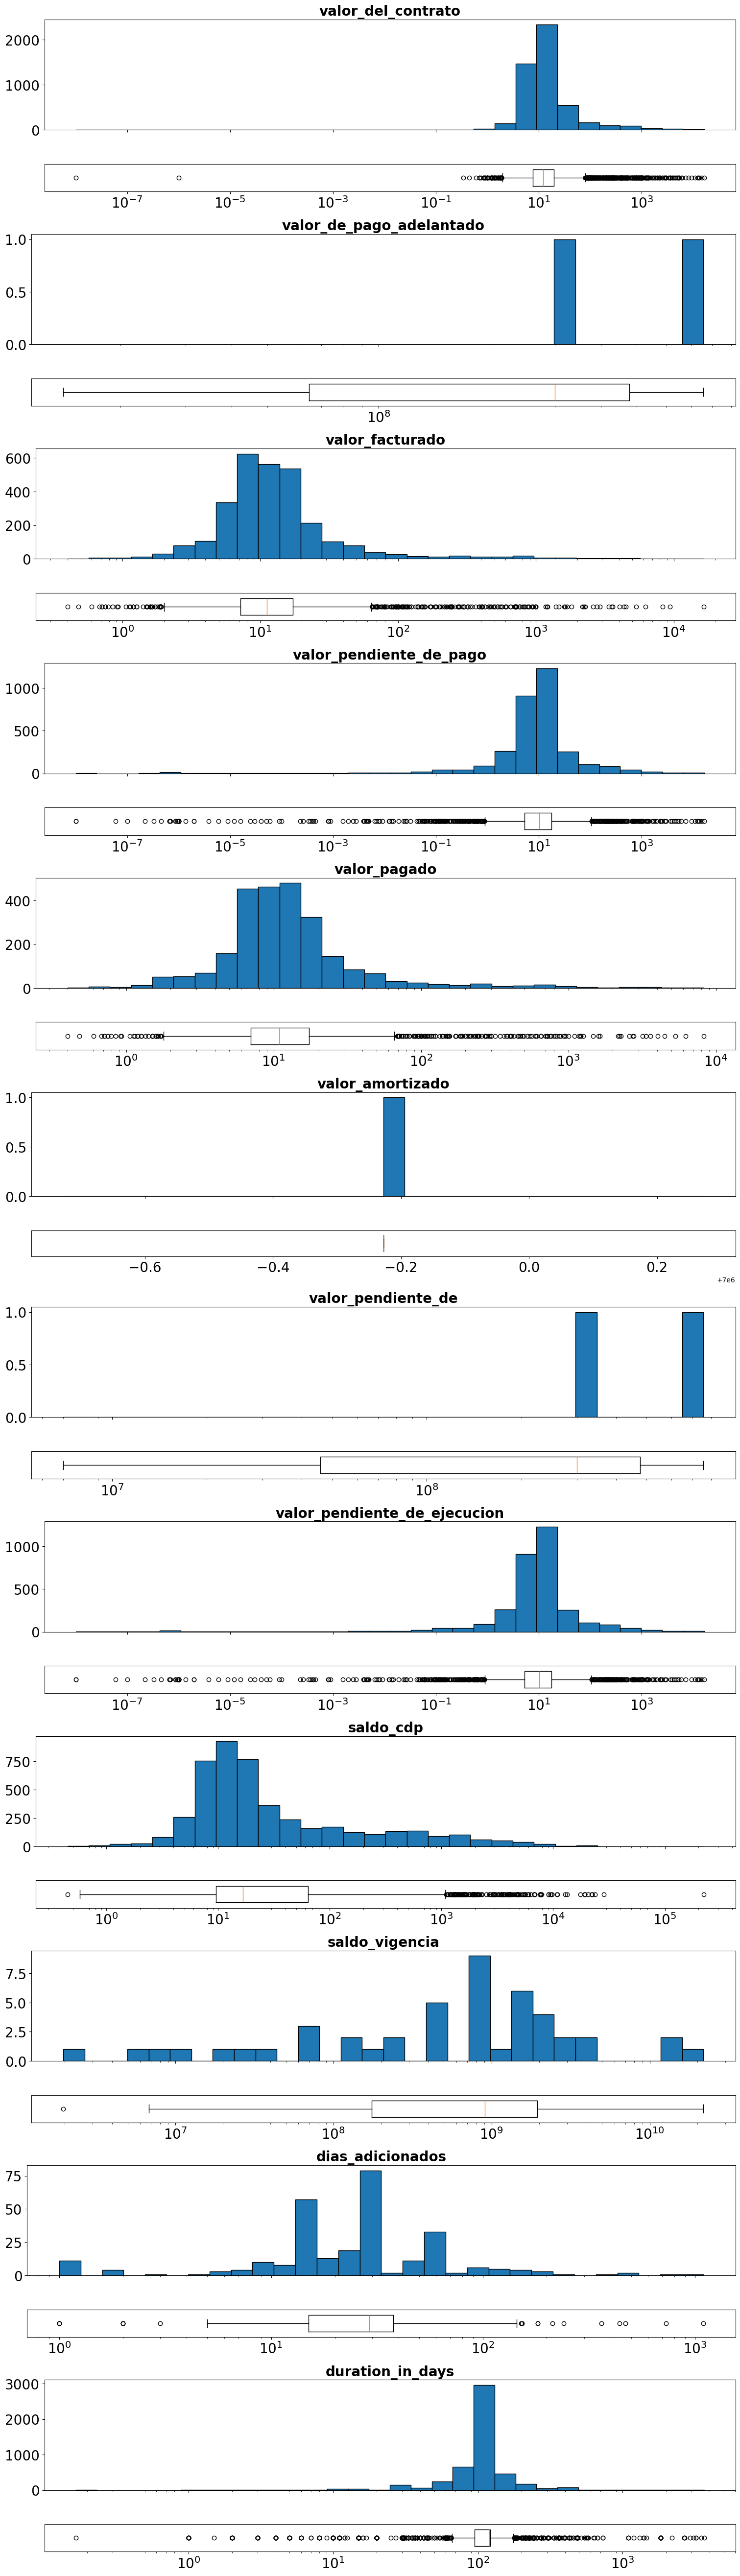

In [27]:
fig, axes = plot_histograms(
    df.select_dtypes(include='number'), 
    x_scale='log', 
    y_scale='linear'
)

In [28]:
df.select_dtypes(include='number').describe()

,valor_del_contrato,valor_de_pago_adelantado,valor_facturado,valor_pendiente_de_pago,valor_pagado,valor_amortizado,valor_pendiente_de,valor_pendiente_de_ejecucion,saldo_cdp,saldo_vigencia,dias_adicionados,duration_in_days
count,5000.000000,5.000000e+03,5000.000000,5000.000000,5000.000000,5.000000e+03,5.000000e+03,5000.000000,5000.000000,5.000000e+03,5000.00000,5000.000000
mean,79.610326,2.142850e+05,36.173271,52.715703,26.894623,1.400000e+03,2.128850e+05,52.715703,331.264960,2.209324e+07,2.48480,127.913834
std,596.632923,1.152208e+07,364.446975,546.245543,234.500063,9.899495e+04,1.152083e+07,546.245543,3403.272725,4.834677e+08,23.97199,164.011987
min,0.000000,0.000000e+00,0.000000,-0.343333,0.000000,0.000000e+00,0.000000e+00,-0.343333,0.000000,0.000000e+00,0.00000,0.166680
25%,7.619322,0.000000e+00,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,8.400000,0.000000e+00,0.00000,95.000000
50%,12.250000,0.000000e+00,5.981229,4.858448,2.000000,0.000000e+00,0.000000e+00,4.858448,15.200000,0.000000e+00,0.00000,120.000000
75%,19.457421,0.000000e+00,12.744143,12.864000,11.154837,0.000000e+00,0.000000e+00,12.864000,51.240131,0.000000e+00,0.00000,122.000000
max,16444.965620,7.574250e+08,16444.965620,16444.965620,8268.549502,7.000000e+06,7.574250e+08,16444.965620,222444.458289,2.187150e+10,1095.00000,3650.000000


### Created millions per day

In [29]:
#df.columns

In [30]:
df['millions_per_day'] =  df['valor_del_contrato'] / df['duration_in_days'] 

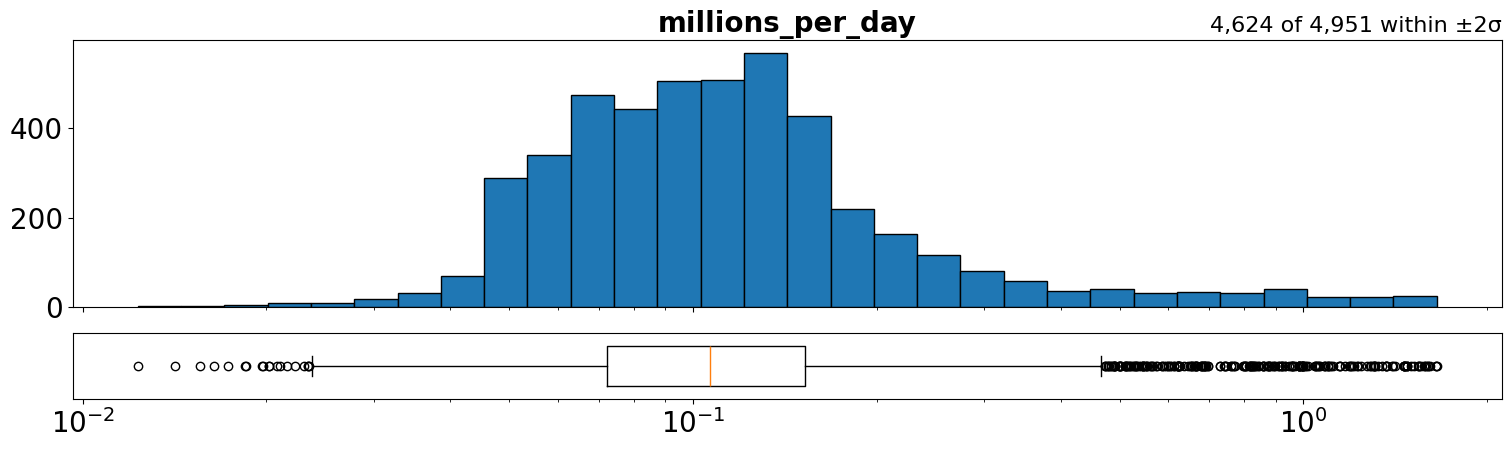

In [31]:
fig, axes = plot_histograms(
    df['millions_per_day'],
    x_scale='log', 
    y_scale='linear',
    n_std=2,
)
summ = df['millions_per_day'].describe()


In [32]:
summ

count    5000.000000
mean        0.694221
std         5.608669
min         0.000000
25%         0.072147
50%         0.113333
75%         0.166667
max       269.980529
Name: millions_per_day, dtype: float64

In [33]:
print("Costo del día de trabajo (equivalente)\n")
print(f"El contrato promedio pagó COP ${(summ.iloc[1]*1e6):,.1f}")
print(f"\n25% de los contratos pagaron menos de  COP ${(summ.iloc[4]*1e6):,.1f}")
print(f"50% de los contratos pagaron menos de  COP ${(summ.iloc[5]*1e6):,.1f}")
print(f"75% de los contratos pagaron menos de  COP ${(summ.iloc[6]*1e6):,.1f}")

print(f"\nEl contrato más caro pagó  COP ${(summ.iloc[7]*1e6):,.1f} por día")
print(f"El contrato más barato pagó  COP ${(summ.iloc[3]*1e6):,.1f} por día")

Costo del día de trabajo (equivalente)

El contrato promedio pagó COP $694,221.3

25% de los contratos pagaron menos de  COP $72,147.1
50% de los contratos pagaron menos de  COP $113,333.3
75% de los contratos pagaron menos de  COP $166,666.7

El contrato más caro pagó  COP $269,980,529.4 por día
El contrato más barato pagó  COP $0.0 por día


## Cleaning no definido to NaN

In [34]:
import numpy as np

pattern = r"(?i)^\s*(no definido)?\s*$"
df.replace(to_replace=pattern, value=np.nan, regex=True, inplace=True)

C:\Users\DAvega01\AppData\Local\Temp\ipykernel_51148\3692643937.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.replace(to_replace=pattern, value=np.nan, regex=True, inplace=True)


In [35]:
threshold = 0.5  # 50%
cols_to_show = df.columns[df.isna().mean() > threshold]
df[cols_to_show].isna().sum()/df.shape[0]

domicilio_representante_legal                                      0.6112
nombre_ordenador_de_pago                                           1.0000
tipo_de_documento_ordenador_de_pago                                1.0000
n_mero_de_documento_ordenador_de_pago                              1.0000
descripcion_documentos_tipo                                        0.9960
criterios_de_sostenibilidad_ambiental                              0.9804
requisitos_ambientales_en_las_especificaciones_t_cnicas            0.9980
criterios_ambientales_en_la_evaluaci_n_de_las_ofertas              0.9980
obligaciones_contractuales_o_poscontractuales_a_nivel_ambiental    0.9980
uso_de_etiquetado_ecol_gico                                        0.9980
fecha_inicio_liquidacion                                           0.8764
fecha_fin_liquidacion                                              0.8764
fecha_de_notificaci_n_de_prorrogaci_n                              0.9252
fecha_inicio_obligaciones_posconsumo  

In [36]:
df.drop(columns=cols_to_show, inplace=True)
print(f'{df.shape[1]} columns left') 

80 columns left


# Dataset exploration

## Create some sets to explore

In [37]:
cols_values = df.columns[df.columns.str.contains(r'valor', case=False, na=False)]
cols_dates = df.columns[df.columns.str.contains(r'fecha', case=False, na=False)]
cols_entity = ['nombre_entidad', 'nit_entidad', 'codigo_entidad', 'orden', 'sector', 'rama', 'entidad_centralizada']
cols_location = ['departamento', 'ciudad', 'localizaci_n', 'direcci_n_de_ejecuci_n_del_contrato']
cols_id = ['proceso_de_compra', 'id_contrato', 'referencia_del_contrato', 'estado_contrato', 'urlproceso', 'ultima_actualizacion']
cols_process = ['codigo_de_categoria_principal', 'descripcion_del_proceso', 'objeto_del_contrato', 'tipo_de_contrato', 'modalidad_de_contratacion', 'justificacion_modalidad_de', 'condiciones_de_entrega', 'documentos_tipo', 'el_contrato_puede_ser_prorrogado', 'liquidaci_n', 'reversion']
cols_supplier = ['proveedor_adjudicado', 'tipodocproveedor', 'documento_proveedor', 'codigo_proveedor', 'es_grupo', 'es_pyme']
cols_people = ['nombre_representante_legal', 'nacionalidad_representante_legal', 'tipo_de_identificaci_n_representante_legal', 'identificaci_n_representante_legal', 'g_nero_representante_legal', 'nombre_ordenador_del_gasto', 'tipo_de_documento_ordenador_del_gasto', 'n_mero_de_documento_ordenador_del_gasto', 'nombre_supervisor', 'tipo_de_documento_supervisor', 'n_mero_de_documento_supervisor']
cols_budget_bank = ['origen_de_los_recursos', 'destino_gasto', 'presupuesto_general_de_la_nacion_pgn', 'sistema_general_de_participaciones', 'sistema_general_de_regal_as', 'recursos_propios_alcald_as_gobernaciones_y_resguardos_ind_genas_', 'recursos_de_credito', 'recursos_propios', 'saldo_cdp_millions', 'habilita_pago_adelantado', 'nombre_del_banco', 'tipo_de_cuenta', 'n_mero_de_cuenta']
cols_policy = ['espostconflicto', 'puntos_del_acuerdo', 'pilares_del_acuerdo', 'obligaci_n_ambiental', 'obligaciones_postconsumo', 'obligaciones_posconsumo']
cols_duration = df.columns[df.columns.str.contains(r'dura', case=False, na=False)]

## Questions

### Are contract IDs unique in this extract?
Yes, they are unique

### How many values, dates, and added-day fields are missing?

In [38]:
df.select_dtypes(include=['number', 'datetime']).info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 17 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   fecha_de_firma                5000 non-null   datetime64[ns]
 1   fecha_de_inicio_del_contrato  4954 non-null   datetime64[ns]
 2   fecha_de_fin_del_contrato     5000 non-null   datetime64[ns]
 3   valor_del_contrato            5000 non-null   float64       
 4   valor_de_pago_adelantado      5000 non-null   float64       
 5   valor_facturado               5000 non-null   float64       
 6   valor_pendiente_de_pago       5000 non-null   float64       
 7   valor_pagado                  5000 non-null   float64       
 8   valor_amortizado              5000 non-null   float64       
 9   valor_pendiente_de            5000 non-null   float64       
 10  valor_pendiente_de_ejecucion  5000 non-null   float64       
 11  saldo_cdp                     

#### Start date nulls check

Only a few in fecha_de_inicio_del_contrato. But those have fecha_de_fin_del_contrato so I guess those did not last more than a day. I will check this:

In [39]:
without_start = df[df['fecha_de_inicio_del_contrato'].isna()].copy()

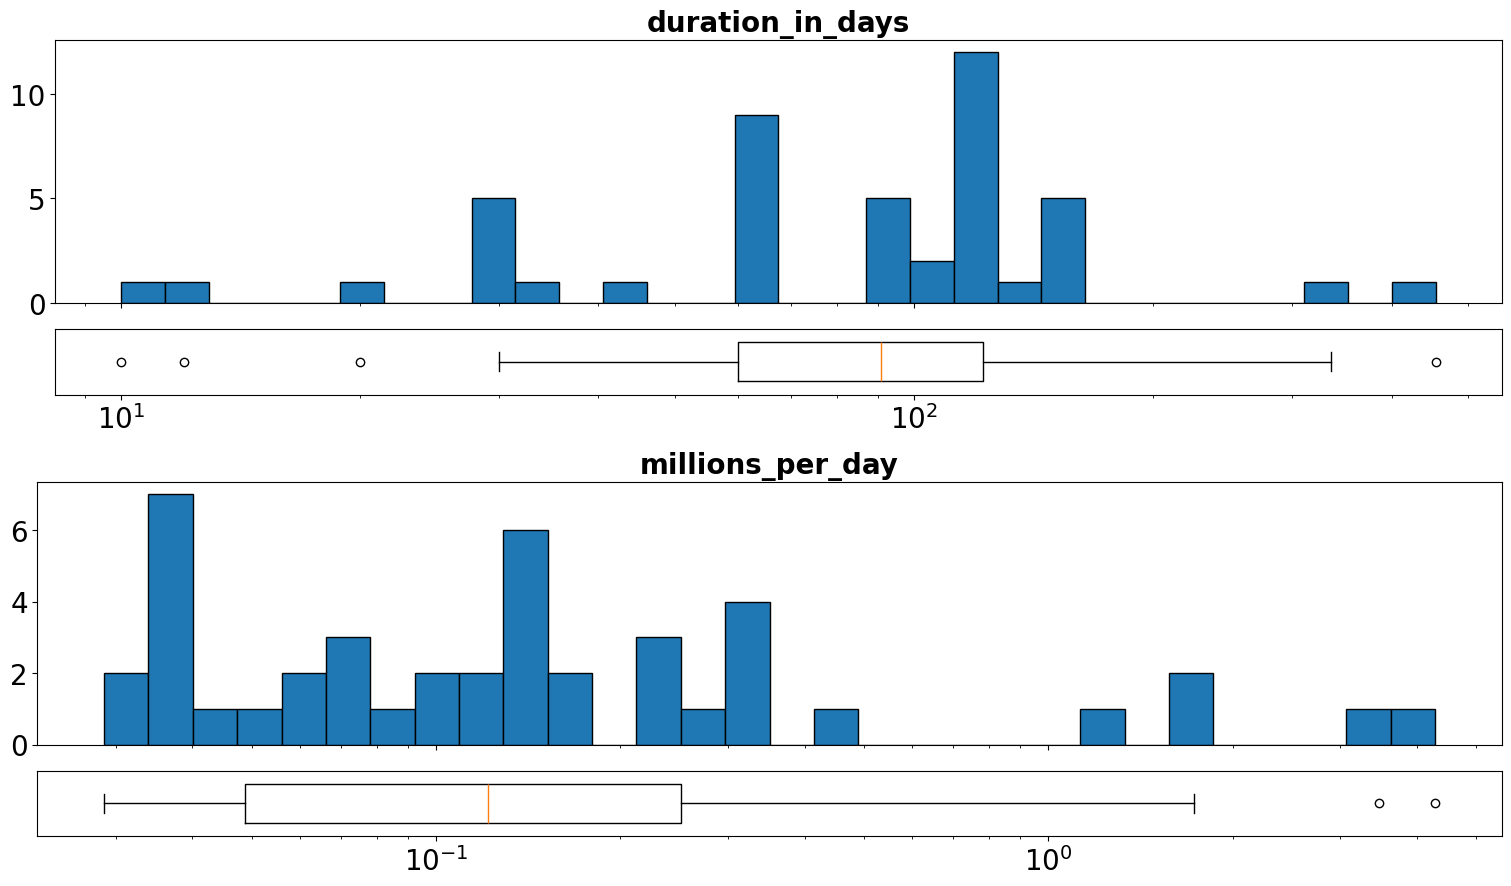

In [40]:
fig, axes = plot_histograms(
    without_start[['duration_in_days','fecha_de_fin_del_contrato','millions_per_day']],
    x_scale='log', 
    y_scale='linear'
)

Ok so they do have a duration. There are two options as I see it: they forgot to input the start or they did not have the information of the start of contract and that can be suspicious

In [41]:
without_start['fecha_de_fin_del_contrato'].value_counts().head(10)

fecha_de_fin_del_contrato
2022-12-31 23:59:00    8
2022-09-30 00:00:00    5
2022-12-31 12:00:00    3
2022-08-31 00:00:00    2
2022-12-15 12:00:00    2
2022-08-31 12:00:00    2
2022-11-29 12:00:00    1
2022-12-31 18:00:00    1
2023-12-31 23:59:00    1
2022-09-14 12:00:00    1
Name: count, dtype: int64

Interesting... we'll have to come back to this later. Some of those are quite in the end of the year or end of month with weird hours. Not sure if the hours are something common in the dataset (maybe everybody puts any hour for the date), let me check: 

In [42]:
df['fecha_de_fin_del_contrato'].dt.time.value_counts().head(10)/df.shape[0]*100

fecha_de_fin_del_contrato
23:59:00    48.16
12:00:00    20.06
18:00:00     7.36
11:59:00     6.64
23:00:00     6.38
00:00:00     2.70
17:00:00     1.72
19:00:00     1.54
11:00:00     0.92
06:00:00     0.68
Name: count, dtype: float64

Yes... I don't think the time means much as it seems in the whole database more than 70% of them are variations of 00:00 or 12:00 (or close to that I mean). The date keeps being interesting, however

In [43]:
df['fecha_de_fin_del_contrato'].dt.date.value_counts().head(10)/df.shape[0]*100

fecha_de_fin_del_contrato
2022-12-30    17.76
2022-12-31    16.96
2022-12-15     7.00
2022-12-29     6.94
2022-11-30     4.84
2022-12-20     4.68
2022-12-16     2.32
2022-10-31     2.12
2022-12-23     1.80
2022-09-30     1.56
Name: count, dtype: float64

Ok... definitely many with end of year dates. If they are related with one year contracts that makes sense.

In [44]:
without_start['fecha_de_firma'].isna().sum()

np.int64(0)

Ok. All of them have a sign date so I guess that one is the start of the contract

In [45]:
without_start['calculated_duration'] = (without_start['fecha_de_fin_del_contrato'] - without_start['fecha_de_firma']).dt.days

In [46]:
without_start[['calculated_duration','duration_in_days']].head()

,calculated_duration,duration_in_days
171,107,335.5
223,0,60.0
229,30,60.0
253,0,60.0
262,30,90.0


Ok. Something does not match here. Let's have a difference column and sort by that. We can later come back to it 

In [47]:
without_start['diff_duration_from_calculated']=(without_start['calculated_duration']-without_start['duration_in_days'])

In [48]:
#without_start.columns

In [49]:
cols_values

Index(['valor_del_contrato', 'valor_de_pago_adelantado', 'valor_facturado',
       'valor_pendiente_de_pago', 'valor_pagado', 'valor_amortizado',
       'valor_pendiente_de', 'valor_pendiente_de_ejecucion'],
      dtype='object')

In [50]:
without_start[cols_values].head()

,valor_del_contrato,valor_de_pago_adelantado,valor_facturado,valor_pendiente_de_pago,valor_pagado,valor_amortizado,valor_pendiente_de,valor_pendiente_de_ejecucion
171,13.750968,0.0,0.0,13.750968,0.0,0.0,0.0,13.750968
223,2.100000,0.0,0.0,2.100000,0.0,0.0,0.0,2.100000
229,2.200000,0.0,0.0,2.200000,0.0,0.0,0.0,2.200000
253,2.200000,0.0,0.0,2.200000,0.0,0.0,0.0,2.200000
262,3.300000,0.0,0.0,3.300000,0.0,0.0,0.0,3.300000


In [51]:
without_start[cols_values.to_list() + ['diff_duration_from_calculated']].sort_values(by='diff_duration_from_calculated').head()

,valor_del_contrato,valor_de_pago_adelantado,valor_facturado,valor_pendiente_de_pago,valor_pagado,valor_amortizado,valor_pendiente_de,valor_pendiente_de_ejecucion,diff_duration_from_calculated
171,13.750968,0.0,0.0,13.750968,0.0,0.0,0.0,13.750968,-228.5
223,2.100000,0.0,0.0,2.100000,0.0,0.0,0.0,2.100000,-60.0
253,2.200000,0.0,0.0,2.200000,0.0,0.0,0.0,2.200000,-60.0
262,3.300000,0.0,0.0,3.300000,0.0,0.0,0.0,3.300000,-60.0
330,3.300000,0.0,0.0,3.300000,0.0,0.0,0.0,3.300000,-60.0


What about end dates minus start dates, do them match the duration of the contract? 

In [83]:
df['calculated_duration'] = (df['fecha_de_fin_del_contrato'] - df['fecha_de_inicio_del_contrato']).dt.days

In [84]:
df['calculated_duration'] == df['duration_in_days'] 

0        True
1       False
2       False
3       False
4       False
        ...  
4995    False
4996    False
4997    False
4998    False
4999    False
Length: 5000, dtype: bool

In [85]:
df['diff_duration_from_calculated']=(df['calculated_duration']-df['duration_in_days'])

In [89]:
weird_durations = df[['diff_duration_from_calculated', 'calculated_duration', 'dias_adicionados']+cols_dates.tolist()+cols_duration.tolist()][df['diff_duration_from_calculated']!=0].sort_values(by="diff_duration_from_calculated", ascending = False)

In [93]:
weird_durations['calculated_duration']-weird_durations['dias_adicionados']-weird_durations['duration_in_days']

3886    182.0
163     594.5
152     581.0
3205    508.0
1994    501.5
        ...  
3996      NaN
4192      NaN
4228      NaN
4248      NaN
4720      NaN
Length: 4069, dtype: float64

In [96]:
weird_durations.dropna(inplace=True)

In [97]:
weird_durations

,diff_duration_from_calculated,calculated_duration,dias_adicionados,fecha_de_firma,fecha_de_inicio_del_contrato,fecha_de_fin_del_contrato,duraci_n_del_contrato,duration_in_days
3886,1277.0,1948.0,1095,2022-08-31 12:06:44.628,2022-08-31 13:35:00,2027-12-31 23:58:00,22 Mes(es),671.0
163,624.5,716.0,30,2022-08-30 08:41:34.746,2022-09-14 08:00:00,2024-08-30 22:59:00,3 Mes(es),91.5
152,581.0,1209.0,0,2022-08-30 08:38:20.805,2022-09-09 12:00:00,2025-12-31 23:59:00,628 Dia(s),628.0
3205,508.0,553.0,0,2022-08-31 08:53:20.907,2022-08-31 09:00:00,2024-03-06 23:59:00,45 Dia(s),45.0
1994,501.5,898.0,0,2022-08-30 16:58:25.027,2022-12-23 12:00:00,2025-06-08 23:59:00,13 Mes(es),396.5
...,...,...,...,...,...,...,...,...
1811,-692.0,1133.0,0,2022-08-30 16:25:19.272,2022-09-15 08:00:00,2025-10-22 23:00:00,5 Año(s),1825.0
3154,-2979.5,101.0,11,2022-08-31 08:26:01.096,2022-09-05 08:00:00,2022-12-15 12:00:00,101 Mes(es),3080.5
3752,-3096.5,106.0,0,2022-08-31 11:30:58.572,2022-08-31 12:00:00,2022-12-15 18:00:00,105 Mes(es),3202.5
3301,-3097.5,105.0,0,2022-08-31 09:27:09.551,2022-09-01 08:00:00,2022-12-15 18:00:00,105 Mes(es),3202.5


### Are there zero or negative contract values?

In [53]:
df[df['valor_del_contrato']<=0].shape

(49, 80)

In [54]:
df['proceso_de_compra'][df['valor_del_contrato']<=0].isna().sum()

np.int64(0)

Yes. 49 contracts. Interesting. There is a 'proceso_de_compra' so I guess I can check that later

### Do any end dates precede start dates?

In [55]:
df_fechas = df.filter(regex=f"(?i)fecha")

In [56]:
df_fechas.columns

Index(['fecha_de_firma', 'fecha_de_inicio_del_contrato',
       'fecha_de_fin_del_contrato'],
      dtype='object')

In [57]:
df[df['fecha_de_fin_del_contrato']<df['fecha_de_inicio_del_contrato']]

,nombre_entidad,nit_entidad,departamento,ciudad,localizaci_n,orden,sector,rama,entidad_centralizada,proceso_de_compra,...,tipo_de_documento_ordenador_del_gasto,n_mero_de_documento_ordenador_del_gasto,nombre_supervisor,tipo_de_documento_supervisor,n_mero_de_documento_supervisor,documentos_tipo,direcci_n_de_ejecuci_n_del_contrato,obligaciones_posconsumo,duration_in_days,millions_per_day


No. Next please

### Which contract types and procurement methods dominate?

In [58]:
df_process = df[cols_process].copy()

In [59]:
df_process.head()

,codigo_de_categoria_principal,descripcion_del_proceso,objeto_del_contrato,tipo_de_contrato,modalidad_de_contratacion,justificacion_modalidad_de,condiciones_de_entrega,documentos_tipo,el_contrato_puede_ser_prorrogado,liquidaci_n,reversion
0,V1.80111701,PRESTACIÓN DE SERVICIOS PROFESIONALES PARA ASE...,PRESTACIÓN DE SERVICIOS PROFESIONALES PARA ASE...,Prestación de servicios,Contratación directa,Servicios profesionales y apoyo a la gestión,NXTWY.DLVY.6,No,No,No,No
1,V1.82101900,PRESTACIÓN DEL SERVICIO DE MONITOREO DE MEDIOS...,PRESTACIÓN DEL SERVICIO DE MONITOREO DE MEDIOS...,Prestación de servicios,Contratación régimen especial,Regla aplicable,NXTWY.DLVY.2,No,Si,Si,No
2,V1.80161500,Prestación de servicios profesionales para el ...,Prestación de servicios profesionales para el ...,Prestación de servicios,Contratación régimen especial,Regla aplicable,NXTWY.DLVY.2,No,Si,No,No
3,V1.80161500,Prestación de servicios profesionales para apo...,Prestación de servicios profesionales para apo...,Prestación de servicios,Contratación régimen especial,Regla aplicable,NXTWY.DLVY.2,No,Si,No,No
4,V1.80161500,Prestación de servicios profesionales para la ...,Prestación de servicios profesionales para la ...,Prestación de servicios,Contratación régimen especial,Regla aplicable,NXTWY.DLVY.2,No,No,No,No


In [60]:
df_process.nunique().sort_values()

documentos_tipo                        2
reversion                              2
liquidaci_n                            2
el_contrato_puede_ser_prorrogado       2
modalidad_de_contratacion             11
condiciones_de_entrega                13
tipo_de_contrato                      14
justificacion_modalidad_de            21
codigo_de_categoria_principal        647
descripcion_del_proceso             4259
objeto_del_contrato                 4292
dtype: int64

In [61]:
df_process.groupby(['modalidad_de_contratacion', 'tipo_de_contrato', 'justificacion_modalidad_de']).size().sort_values(ascending=False).head(10)


modalidad_de_contratacion             tipo_de_contrato            justificacion_modalidad_de                             
Contratación directa                  Prestación de servicios     Servicios profesionales y apoyo a la gestión               3875
Contratación régimen especial         Prestación de servicios     Regla aplicable                                             233
Mínima cuantía                        Prestación de servicios     Presupuesto inferior al 10% de la menor cuantía             123
Contratación directa                  Otro                        Contratos o convenios Interadministrativos (valor cero)      92
Contratación régimen especial         Decreto 092 de 2017         Decreto 092 de 2017                                          82
Mínima cuantía                        Compraventa                 Presupuesto inferior al 10% de la menor cuantía              81
                                      Suministros                 Presupuesto inferior al 10% de l

In [62]:
print(f'About {df_process.groupby(['modalidad_de_contratacion', 'tipo_de_contrato', 'justificacion_modalidad_de']).size().sort_values(ascending=False).head(10).sum()/df.shape[0]*100}% of the contracts fall into these 10 combinations listed')

About 93.0% of the contracts fall into these 10 combinations listed


In [63]:
df.groupby(['modalidad_de_contratacion', 'tipo_de_contrato', 'justificacion_modalidad_de', 'sector']).size().sort_values(ascending=False)

modalidad_de_contratacion            tipo_de_contrato         justificacion_modalidad_de                                                                  sector                          
Contratación directa                 Prestación de servicios  Servicios profesionales y apoyo a la gestión                                                Servicio Público                    1264
                                                                                                                                                          No aplica/No pertenece               989
                                                                                                                                                          deportes                             354
                                                                                                                                                          Educación Nacional                   235
                                 

In [64]:
to_remove = {'ciudad', 'localizaci_n', 'direcci_n_de_ejecuci_n_del_contrato'}
subset_loc = [c for c in cols_location if c not in to_remove]

df.groupby(subset_loc).size().sort_values(ascending=False).head(10)

departamento
Distrito Capital de Bogotá                  1054
Antioquia                                    465
Valle del Cauca                              426
Santander                                    393
Bolívar                                      247
Cundinamarca                                 219
Meta                                         214
San Andrés, Providencia y Santa Catalina     202
Tolima                                       183
Risaralda                                    170
dtype: int64

Ok. Interesting but I think I need to understand more. Maybe a bubble graph would be interesting.

In [65]:
#%pip install ipywidgets plotly

In [66]:
import numpy as np
import plotly.express as px
import ipywidgets as widgets
from IPython.display import display

# 1. Fast column lists (avoids scanning huge text columns like 'objeto_del_contrato')
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()

candidate_cats = [
    'departamento', 'orden', 'sector', 'rama', 'entidad_centralizada',
    'estado_contrato', 'tipo_de_contrato', 'modalidad_de_contratacion',
    'es_grupo', 'es_pyme', 'habilita_pago_adelantado', 'liquidaci_n',
    'obligaci_n_ambiental', 'origen_de_los_recursos', 'destino_gasto',
    'espostconflicto', 'el_contrato_puede_ser_prorrogado', 'g_nero_representante_legal'
]
cat_cols = [c for c in candidate_cats if c in df.columns]

# 2. Dropdown widgets
cat_dropdown = widgets.Dropdown(options=cat_cols, value='tipo_de_contrato', description='Category:')
x_dropdown = widgets.Dropdown(options=num_cols, value='duration_in_days' if 'duration_in_days' in num_cols else num_cols, description='X-Axis:')
y_dropdown = widgets.Dropdown(options=num_cols, value='valor_del_contrato' if 'valor_del_contrato' in num_cols else num_cols, description='Y-Axis:')
size_dropdown = widgets.Dropdown(options=num_cols, value='millions_per_day' if 'millions_per_day' in num_cols else num_cols, description='Size:')
agg_dropdown = widgets.Dropdown(options=['mean', 'sum', 'median', 'count'], value='mean', description='Agg:')

# 3. Use FigureWidget for instant updates without re-rendering from scratch
fig = px.scatter(title="Loading...")
fig_widget = go.FigureWidget(fig) if 'go' in globals() else None

def update_bubble_chart(category, x_col, y_col, size_col, agg_func):
    cols_needed = list(dict.fromkeys([x_col, y_col, size_col]))
    grouped = df.groupby(category, dropna=False, observed=True)[cols_needed].agg(agg_func).reset_index()
    grouped['_bubble_size'] = grouped[size_col].clip(lower=0).fillna(0)
    
    new_fig = px.scatter(
        grouped,
        x=x_col,
        y=y_col,
        size='_bubble_size',
        color=category,
        hover_name=category,
        size_max=55,
        title=f"{y_col} vs {x_col} by {category} ({agg_func})"
    )
    new_fig.update_layout(height=550, template='plotly_white')
    new_fig.show()

ui = widgets.VBox([
    widgets.HBox([cat_dropdown, agg_dropdown]),
    widgets.HBox([x_dropdown, y_dropdown, size_dropdown])
])

out = widgets.interactive_output(
    update_bubble_chart,
    {'category': cat_dropdown, 'x_col': x_dropdown, 'y_col': y_dropdown, 'size_col': size_dropdown, 'agg_func': agg_dropdown}
)

display(ui, out)


Output()

Being the bubble size the "millions per day" measure:

By department, Putumayo and La Guajira seem to have the biggest bubbles (3.48 and 1.93 Millions respectively).

By sector, the "TIC" are the ones dominating visibly with a bubble size of 30.96 Millions. 

By rama, "Legislativo" dominates with 6.24 Millions

By "estado_contrato" Suspended contracts and modified contracts dominate with 2.96 and 1.84 respectively

By "tipo_de_contrato" Obra, Suministros and Consultoria lead with 6.7, 4.6 and 4

By "modalidad_de_contratacion" Licitación pública and "Contratación con regimen especial" lead with 14 and 11 Millions

By "es_grupo" "Yes" wins by a lot 10.7 against 0.6 for "No"

Interestingly, the gender of the legal representative also seems to affect by a lot. "Other" have 7.3M while Men and women have averages under 1M. Could it be because the data of the legal representative is missing? 



### How many contracts have positive added days?

In [67]:
(df['dias_adicionados']!=0).sum()

np.int64(282)

In [68]:
with_aditions = df[df['dias_adicionados']!=0]

In [69]:
print(f'Yes, there are {(df['dias_adicionados']!=0).sum()} contracts representing about {(df['dias_adicionados']!=0).sum()/df.shape[0]*100}% of the contracts')

Yes, there are 282 contracts representing about 5.64% of the contracts


In [70]:
with_aditions['millions_per_day'].mean()

np.float64(1.9437624010710224)

Those don't seem to add up that much to the average but ok. Worth checking anyways, maybe?

### Are enough comparable contracts available within each group?

Interesting question... we can use the same interactive bubble plot as before but using count instead of mean. WIll do that and put my comments here

Now just counting each group across different attributes: 

By rama, "Ejecutivo" dominates with 4069 records

By "tipo_de_contrato" Prestación de servicios dominates with 4324 rows. 

By "modalidad_de_contratacion" "Contratación directa" has 4048 records while the others are very few

By "es_grupo" "No" wins by a lot 4958 against 42 for "Yes"

The gender here also impacts but now I understand why... groups don't have a gender when it comes to legal representative... I thought they did but it seems like they do not